# PMRT v3 - External validation on PhysioNet/CinC Challenge 2018

The five trained v3 fold models (trained on CAP only) are applied **without any retraining or fine-tuning** to a random subset of the CinC 2018 training set (EEG C4-M1, chin EMG, ECG for the labels).

Evaluated: HR, RMSSD, stress index (SI > 1), sleep stage. Not evaluated: disorder head (CinC has no matching disorder labels).

Run order: set `SMOKE_TEST = True` first (5 subjects), check the printed output, then set it to `False` for the full run. Downloaded records are deleted after processing; per-subject results are cached on Drive, so an interrupted run resumes.

In [16]:
# Setup: install packages, mount Google Drive and import the trained v3 module
!pip -q install wfdb neurokit2 h5py
import sys, json, re, time, shutil, warnings, importlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import requests, torch
from pathlib import Path
from fractions import Fraction
from scipy.signal import butter, sosfiltfilt, resample_poly
from sklearn.metrics import (roc_curve, roc_auc_score, average_precision_score, confusion_matrix, cohen_kappa_score,
                             balanced_accuracy_score, f1_score, accuracy_score, recall_score)
import neurokit2 as nk
import wfdb
from google.colab import drive
warnings.filterwarnings("ignore")
drive.mount("/content/drive")
ROOT = Path("/content/drive/MyDrive/sleep_project")
sys.path.insert(0, str(ROOT))
import pmrt_mt3 as M
importlib.reload(M)
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEV)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
device: cuda


In [17]:
# Configuration: subset size, paths and the CAP reference numbers (table05 of the final model)
SMOKE_TEST = False
N_SUBJECTS = 100
SEED = 42
B_BOOT = 200
SEQ_LEN, N_FOLDS, BATCH_SEQ = 12, 5, 24
STAGE_PURITY = 0.95
BASE_URL = "https://physionet.org/files/challenge-2018/1.0.0/training"
RUN_DIR = ROOT / "runs" / "pmrt_mt3_cv5"
CACHE = ROOT / "external_cinc2018" / "cache"
OUT = ROOT / ("external_cinc2018_smoke" if SMOKE_TEST else "external_cinc2018")
TMP = Path("/content/cinc_tmp")
TARGET = 5 if SMOKE_TEST else N_SUBJECTS
for p in (CACHE, OUT, TMP):
    p.mkdir(parents=True, exist_ok=True)
CAP_REF = {"HR MAE (bpm)": 4.300, "HR r": 0.7299, "RMSSD r": 0.2050, "stress AUC": 0.7194,
           "stress AUC (HR-only def.)": 0.7956, "sleep stage acc": 0.7494, "sleep stage kappa": 0.6258,
           "sleep stage macro F1": 0.6931}
print("target subjects:", TARGET, "| output:", OUT)

target subjects: 100 | output: /content/drive/MyDrive/sleep_project/external_cinc2018


In [18]:
# Preprocessing functions identical to the CAP pipeline (cap_preprocess.py): resampling, band-pass, RR detection, HR/RMSSD labels
FS, WIN, CTX = 125, 5, 60
BANDS = {"eeg": (0.5, 30), "emg": (10, 60), "ecg": (0.5, 30)}
norm = lambda l: re.sub(r"[^A-Z0-9]", "", l.upper())

def pick(labels, rules):
    N = [norm(l) for l in labels]
    for rule in rules:
        for i, n in enumerate(N):
            if rule(n):
                return i
    return None

RULES = {
    "eeg": [lambda n: n == "C4M1", lambda n: n == "C4A1", lambda n: n == "C3M2", lambda n: n == "C3A2"],
    "emg": [lambda n: n.startswith("CHIN"), lambda n: n.startswith("EMG")],
    "ecg": [lambda n: n in ("ECG", "ECG1ECG2", "EKG"), lambda n: "ECG" in n or "EKG" in n],
}

def to_fs(x, fs):
    if abs(fs - FS) < 1e-6:
        return x
    fr = Fraction(FS / fs).limit_denominator(2000)
    return resample_poly(x, fr.numerator, fr.denominator)

def bandpass(x, lo, hi):
    sos = butter(2, [lo, min(hi, FS / 2 - 1)], btype="band", fs=FS, output="sos")
    return sosfiltfilt(sos, x)

def rr_series(ecg):
    clean = nk.ecg_clean(ecg, sampling_rate=FS, method="neurokit")
    _, info = nk.ecg_peaks(clean, sampling_rate=FS, method="neurokit")
    peaks = np.asarray(info["ECG_R_Peaks"], dtype=int)
    t = peaks / FS
    rr = np.diff(t)
    ok = (rr > 0.3) & (rr < 2.0)
    med = pd.Series(rr).rolling(11, center=True, min_periods=3).median().values
    ok &= np.abs(rr - med) < 0.2 * med
    return t[1:], rr, ok

def window_labels(starts, rr_t, rr, ok):
    hr, rmssd = np.full(len(starts), np.nan), np.full(len(starts), np.nan)
    for k, s in enumerate(starts):
        m = (rr_t >= s) & (rr_t < s + WIN) & ok
        if m.sum() >= 3:
            hr[k] = 60.0 / rr[m].mean()
        c0, c1 = s + WIN / 2 - CTX / 2, s + WIN / 2 + CTX / 2
        idx = np.where((rr_t >= c0) & (rr_t < c1))[0]
        if len(idx) >= 20:
            pair = ok[idx[1:]] & ok[idx[:-1]] & (np.diff(idx) == 1)
            if pair.sum() >= 15:
                d = np.diff(rr[idx])[pair]
                rmssd[k] = np.sqrt(np.mean(d ** 2)) * 1000.0
    return hr, rmssd

def windows_from_signals(eeg, emg, ecg, codes, fs0):
    n = min(len(eeg), len(emg), len(ecg), len(codes))
    L0 = int(round(WIN * fs0))
    nb = n // L0
    c = codes[:nb * L0].reshape(nb, L0)
    frac = np.stack([(c == k).mean(1) for k in range(1, 5)], 1)
    stage = np.where(frac.max(1) >= STAGE_PURITY, frac.argmax(1), -1)
    sig = {k: bandpass(to_fs(np.asarray(x[:n], dtype=np.float64), fs0), *BANDS[k])
           for k, x in (("eeg", eeg), ("emg", emg), ("ecg", ecg))}
    S = WIN * FS
    nw = min(nb, len(sig["eeg"]) // S)
    if nw == 0:
        return "skip: recording too short"
    w = {k: v[:nw * S].reshape(nw, S) for k, v in sig.items()}
    stage = stage[:nw]
    starts = np.arange(nw) * float(WIN)
    flat = (w["eeg"].std(1) < 0.5) | (w["emg"].std(1) < 0.05) | (w["ecg"].std(1) < 1e-3)
    rr_t, rr, ok = rr_series(sig["ecg"][:nw * S])
    hr, rmssd = window_labels(starts, rr_t, rr, ok)
    no_label = np.isnan(hr) | np.isnan(rmssd)
    keep = (stage >= 0) & ~flat & ~no_label
    counts = {"windows_total": int(nw), "no_sleep_stage": int((stage < 0).sum()), "flat": int(flat.sum()),
              "no_label": int(no_label.sum()), "kept": int(keep.sum())}
    if keep.sum() == 0:
        return f"skip: no valid windows {counts}"
    z = lambda a: ((a[keep] - a[keep].mean()) / a[keep].std()).astype(np.float16)
    return {"eeg": z(w["eeg"]), "emg": z(w["emg"]), "hr": hr[keep].astype(np.float32),
            "rmssd": rmssd[keep].astype(np.float32), "stage": stage[keep].astype(np.int8),
            "t": starts[keep].astype(np.float32), "counts": counts}

In [19]:
# CinC 2018 record handling: download, read signals and sleep stages, process one record into a cached file
def fetch(url, dst, tries=4):
    dst = Path(dst)
    if dst.exists() and dst.stat().st_size > 0:
        return
    for a in range(tries):
        try:
            with requests.get(url, stream=True, timeout=120) as r:
                r.raise_for_status()
                with open(dst, "wb") as f:
                    for ch in r.iter_content(1 << 20):
                        f.write(ch)
            return
        except Exception as e:
            if dst.exists():
                dst.unlink()
            if a == tries - 1:
                raise
            time.sleep(5 * (a + 1))

def show_tree(path):
    import h5py
    with h5py.File(path, "r") as f:
        f.visit(print)

def read_stages(path):
    names = {"wake": 0, "nonrem1": 1, "nonrem2": 2, "nonrem3": 3, "rem": 4}
    try:
        import h5py
        with h5py.File(path, "r") as f:
            g = f["data"]["sleep_stages"]
            arrs = {k: np.asarray(g[k][()]).ravel() for k in names}
    except OSError:
        from scipy.io import loadmat
        m = loadmat(path, squeeze_me=True, struct_as_record=False)
        g = m["data"].sleep_stages
        arrs = {k: np.asarray(getattr(g, k)).ravel() for k in names}
    codes = np.full(len(arrs["wake"]), -1, dtype=np.int8)
    for k, c in names.items():
        codes[arrs[k] > 0] = c
    return codes

def process_record(folder, rec):
    d = TMP / rec
    d.mkdir(parents=True, exist_ok=True)
    try:
        for suf in (".hea", ".mat", "-arousal.mat"):
            fetch(f"{BASE_URL}/{folder}/{rec}{suf}", d / f"{rec}{suf}")
        hdr = wfdb.rdheader(str(d / rec))
        ch = {k: pick(hdr.sig_name, RULES[k]) for k in RULES}
        if any(v is None for v in ch.values()):
            return f"skip: missing channels {[k for k, v in ch.items() if v is None]} in {hdr.sig_name}"
        rd = wfdb.rdrecord(str(d / rec), channels=[ch["eeg"], ch["emg"], ch["ecg"]], physical=True)
        sig = np.nan_to_num(rd.p_signal.astype(np.float64))
        scale = [{"mv": 1e3, "v": 1e6}.get(u.strip().lower(), 1.0) for u in rd.units]
        eeg, emg, ecg = (sig[:, i] * scale[i] for i in range(3))
        codes = read_stages(str(d / f"{rec}-arousal.mat"))
        res = windows_from_signals(eeg, emg, ecg, codes, float(rd.fs))
        if isinstance(res, str):
            return res
        counts = res.pop("counts")
        meta = {"record": rec, "channels": [hdr.sig_name[ch[k]] for k in ("eeg", "emg", "ecg")],
                "units": list(rd.units), "fs": float(rd.fs), **counts}
        np.savez_compressed(CACHE / f"{rec}.npz", meta=json.dumps(meta), **res)
        return f"ok: {counts['kept']}/{counts['windows_total']} windows kept | channels {meta['channels']} units {meta['units']}"
    finally:
        shutil.rmtree(d, ignore_errors=True)

In [20]:
# Select the random subset of the CinC 2018 training records and process them one by one (download, process, delete raw files)
txt = requests.get(f"{BASE_URL}/RECORDS", timeout=60).text
entries = []
for line in txt.split():
    line = line.strip().strip("/")
    if line:
        parts = line.split("/")
        entries.append((parts[0], parts[-1]))
print("records listed:", len(entries), "| first:", entries[:2])
order = np.random.default_rng(SEED).permutation(len(entries))
ok_recs, log = [], []
t_all = time.time()
for i in order:
    if len(ok_recs) >= TARGET:
        break
    folder, rec = entries[i]
    out, skip = CACHE / f"{rec}.npz", CACHE / f"{rec}.skip"
    if out.exists():
        ok_recs.append(rec)
        continue
    if skip.exists():
        continue
    t0 = time.time()
    try:
        status = process_record(folder, rec)
    except Exception as e:
        status = f"error: {type(e).__name__}: {e}"
    if status.startswith("ok"):
        ok_recs.append(rec)
    else:
        skip.write_text(status)
    log.append({"record": rec, "status": status, "sec": round(time.time() - t0, 1)})
    print(f"[{len(ok_recs):3d}/{TARGET}] {rec} {status} ({time.time() - t0:.0f}s)", flush=True)
pd.DataFrame(log).to_csv(OUT / "processing_log.csv", index=False)
print(f"processed subjects: {len(ok_recs)} | total time {(time.time() - t_all) / 60:.1f} min")

records listed: 994 | first: [('tr03-0005', 'tr03-0005'), ('tr03-0029', 'tr03-0029')]
[  6/100] tr03-0933 ok: 3564/5068 windows kept | channels ['C4-M1', 'Chin1-Chin2', 'ECG'] units ['uV', 'uV', 'mV'] (14s)
[  7/100] tr03-0532 ok: 4397/5405 windows kept | channels ['C4-M1', 'Chin1-Chin2', 'ECG'] units ['uV', 'uV', 'mV'] (10s)
[  8/100] tr09-0600 ok: 3188/4776 windows kept | channels ['C4-M1', 'Chin1-Chin2', 'ECG'] units ['uV', 'uV', 'mV'] (11s)
[  9/100] tr05-1233 ok: 2059/5376 windows kept | channels ['C4-M1', 'Chin1-Chin2', 'ECG'] units ['uV', 'uV', 'mV'] (9s)
[ 10/100] tr07-0247 ok: 5126/5677 windows kept | channels ['C4-M1', 'Chin1-Chin2', 'ECG'] units ['uV', 'uV', 'mV'] (11s)
[ 11/100] tr12-0684 ok: 3446/5641 windows kept | channels ['C4-M1', 'Chin1-Chin2', 'ECG'] units ['uV', 'uV', 'mV'] (11s)
[ 12/100] tr11-0347 ok: 4691/5759 windows kept | channels ['C4-M1', 'Chin1-Chin2', 'ECG'] units ['uV', 'uV', 'mV'] (11s)
[ 13/100] tr12-0481 ok: 4277/5286 windows kept | channels ['C4-M1', 

In [21]:
# Assemble the external dataset (X, index) from the cached subjects
parts_x, parts_i = [], []
for rec in sorted(ok_recs):
    z = np.load(CACHE / f"{rec}.npz")
    parts_x.append(np.stack([z["eeg"], z["emg"]], 1))
    parts_i.append(pd.DataFrame({"record": rec, "t": z["t"], "stg": z["stage"].astype(np.int64),
                                 "hr": z["hr"], "rmssd": z["rmssd"]}))
X = np.concatenate(parts_x)
IDX = pd.concat(parts_i, ignore_index=True)
Y = {"hr": np.zeros(len(IDX), np.float32)}
print("X:", X.shape, X.dtype, "| subjects:", IDX.record.nunique(), "| windows:", len(IDX))
print(IDX.groupby("record").size().describe().round(0).to_string())
print("stage share:", IDX.stg.map(dict(enumerate(M.STAGES))).value_counts(normalize=True).round(3).to_dict())
print("HR mean/SD:", round(float(IDX.hr.mean()), 1), round(float(IDX.hr.std()), 1), "| RMSSD median:", round(float(IDX.rmssd.median()), 1))
cap = pd.read_csv(ROOT / "cap_dataset_cache" / "index.csv")
print("CAP HR mean/SD:", round(float(cap.hr.mean()), 1), round(float(cap.hr.std()), 1), "| CAP RMSSD median:", round(float(cap.rmssd.median()), 1))
print("CAP t step (median diff in one record):", np.median(np.diff(np.sort(cap[cap.record == cap.record.iloc[0]].t.to_numpy()))))

X: (409628, 2, 625) float16 | subjects: 100 | windows: 409628
count     100.0
mean     4096.0
std      1088.0
min       623.0
25%      3723.0
50%      4316.0
75%      4732.0
max      5816.0
stage share: {'N2': 0.506, 'N1': 0.189, 'REM': 0.161, 'N3': 0.145}
HR mean/SD: 65.6 11.0 | RMSSD median: 28.9
CAP HR mean/SD: 63.9 9.6 | CAP RMSSD median: 43.2
CAP t step (median diff in one record): 5.0


In [27]:
# Inference in float32 (no autocast) with checks for non-finite inputs and predictions
FOLD = json.loads((ROOT / "folds_5.json").read_text())
ROWS = np.arange(len(IDX))
print("X finite:", bool(np.isfinite(X).all()), "| max |X|:", float(np.abs(X.astype(np.float32)).max()))

@torch.no_grad()
def predict_fp32(model, loader):
    model.eval()
    res, J = {}, []
    for x, mask, _, j in loader:
        out = model(x, mask)
        for k, v in out.items():
            v = v.float()
            res.setdefault(k, []).append((torch.softmax(v, -1) if v.ndim == 2 else v).cpu().numpy())
        J.append(j)
    J = np.concatenate(J)
    o = np.argsort(J, kind="stable")
    return J[o], {k: np.concatenate(v)[o] for k, v in res.items()}

P = {}
for k in range(N_FOLDS):
    rows = M.fold_rows(cap, FOLD, k, N_FOLDS)
    tg = M.Targets(cap, rows["train"])
    model = M.PMRTTemporal(L=SEQ_LEN, stage_head=True).to(DEV)
    ck = torch.load(RUN_DIR / f"fold{k}" / "best_stress.pt", map_location=DEV, weights_only=False)
    model.load_state_dict(ck["model"])
    loader = M.SequenceBatches(X, Y, IDX, ROWS, BATCH_SEQ, DEV, L=SEQ_LEN, train=False)
    t0 = time.time()
    j, p = predict_fp32(model, loader)
    assert len(j) == len(IDX) and (j == ROWS).all()
    hr, rm = tg.decode(p["hr"], p["rmssd"])
    bad = ~(np.isfinite(hr) & np.isfinite(rm) & np.isfinite(p["stg"]).all(1))
    P[k] = {"hr": hr, "rmssd": rm, "stg": p["stg"]}
    print(f"fold model {k}: {time.time() - t0:.0f}s | non-finite windows: {int(bad.sum())} in records {sorted(set(IDX.record[bad]))} | pred HR mean {np.nanmean(hr):.1f}")
    del model
    torch.cuda.empty_cache()
P["ens"] = {"hr": np.mean([P[k]["hr"] for k in range(N_FOLDS)], 0),
            "rmssd": np.exp(np.mean([np.log(P[k]["rmssd"]) for k in range(N_FOLDS)], 0)),
            "stg": np.mean([P[k]["stg"] for k in range(N_FOLDS)], 0)}
print("ensemble non-finite HR windows:", int((~np.isfinite(P["ens"]["hr"])).sum()))

X finite: True | max |X|: 441.0
fold model 0: 57s | non-finite windows: 0 in records [] | pred HR mean 65.0
fold model 1: 58s | non-finite windows: 0 in records [] | pred HR mean 64.7
fold model 2: 59s | non-finite windows: 0 in records [] | pred HR mean 66.3
fold model 3: 59s | non-finite windows: 0 in records [] | pred HR mean 66.2
fold model 4: 59s | non-finite windows: 0 in records [] | pred HR mean 65.7
ensemble non-finite HR windows: 0


In [28]:
# Metric functions with the same definitions as pmrt_final_results (within-subject z-scores, SI = z(HR) - z(RMSSD), stress if SI > 1)
def zin(d, c, by="record"):
    g = d.groupby(by)[c]
    return ((d[c] - g.transform("mean")) / g.transform("std")).fillna(0.0)

def frame(pr):
    d = IDX[["record", "t", "stg", "hr", "rmssd"]].copy()
    d["hr_pred"], d["rmssd_pred"] = pr["hr"], pr["rmssd"]
    for i, s in enumerate(M.STAGES):
        d[f"p_{s}"] = pr["stg"][:, i]
    d["si_true"] = zin(d, "hr") - zin(d, "rmssd")
    d["si_pred"] = zin(d, "hr_pred") - zin(d, "rmssd_pred")
    d["zhr_true"], d["zhr_pred"] = zin(d, "hr"), zin(d, "hr_pred")
    d["y_stress"], d["y_hr"] = (d.si_true > 1).astype(int), (d.zhr_true > 1).astype(int)
    d["stage_pred"] = d[[f"p_{s}" for s in M.STAGES]].to_numpy().argmax(1)
    return d

def safe_auc(y, s):
    return roc_auc_score(y, s) if len(np.unique(y)) > 1 else np.nan

def core(d):
    hr = M.reg_metrics(d.hr.to_numpy(), d.hr_pred.to_numpy())
    rm = M.reg_metrics(d.rmssd.to_numpy(), d.rmssd_pred.to_numpy())
    return {"HR MAE (bpm)": hr["MAE"], "HR r": hr["r"], "RMSSD r": rm["r"],
            "stress AUC": safe_auc(d.y_stress, d.si_pred), "stress AUC (HR-only def.)": safe_auc(d.y_hr, d.zhr_pred),
            "sleep stage acc": accuracy_score(d.stg, d.stage_pred), "sleep stage kappa": cohen_kappa_score(d.stg, d.stage_pred),
            "sleep stage macro F1": f1_score(d.stg, d.stage_pred, average="macro")}

def full(d):
    hr = M.reg_metrics(d.hr.to_numpy(), d.hr_pred.to_numpy())
    rm = M.reg_metrics(d.rmssd.to_numpy(), d.rmssd_pred.to_numpy())
    yp = (d.si_pred > 1).astype(int)
    out = core(d)
    out.update({"HR RMSE (bpm)": hr["RMSE"], "HR bias (bpm)": hr["ME"], "HR R2": hr["R2"],
                "RMSSD MAE (ms)": rm["MAE"], "stress AP": average_precision_score(d.y_stress, d.si_pred),
                "stress bal. acc": balanced_accuracy_score(d.y_stress, yp), "stress F1": f1_score(d.y_stress, yp),
                "stress sensitivity": recall_score(d.y_stress, yp), "stress specificity": recall_score(1 - d.y_stress, 1 - yp)})
    return out

def bootstrap(d, B, seed):
    groups = {r: g for r, g in d.groupby("record").indices.items()}
    keys = list(groups)
    rng = np.random.default_rng(seed)
    rows = []
    for _ in range(B):
        ix = np.concatenate([groups[keys[i]] for i in rng.integers(0, len(keys), len(keys))])
        rows.append(core(d.iloc[ix]))
    b = pd.DataFrame(rows)
    return b.quantile(0.025), b.quantile(0.975)

In [29]:
# Results: ensemble of the five CAP-trained fold models, each fold model separately, baselines and the CAP reference
D = {"ensemble": frame(P["ens"])}
for k in range(N_FOLDS):
    D[f"fold{k}"] = frame(P[k])
E = D["ensemble"]
res_full = full(E)
lo, hi = bootstrap(E, B_BOOT, SEED)
tab = pd.DataFrame({"CinC 2018 (ensemble)": pd.Series(res_full), "CI low": lo, "CI high": hi, "CAP CV (reference)": pd.Series(CAP_REF)})
tab = tab.loc[list(res_full)]
print(tab.round(3).to_string())
folds = pd.DataFrame({n: core(d) for n, d in D.items()})
print("\nPer fold model:")
print(folds.round(3).to_string())
base_hr = float(cap.hr.median())
base_rm = float(cap.rmssd.median())
subj_mean = E.groupby("record").hr.transform("mean")
base = pd.Series({"HR MAE, CAP-median predictor (bpm)": np.mean(np.abs(E.hr - base_hr)),
                  "HR MAE, per-subject mean oracle (bpm)": np.mean(np.abs(E.hr - subj_mean)),
                  "RMSSD MAE, CAP-median predictor (ms)": np.mean(np.abs(E.rmssd - base_rm)),
                  "RMSSD MAE, model (ms)": res_full["RMSSD MAE (ms)"]})
print("\nBaselines:")
print(base.round(3).to_string())
per = E.groupby("record").apply(lambda g: pd.Series({
    "windows": len(g), "HR MAE": np.mean(np.abs(g.hr - g.hr_pred)),
    "HR r": np.corrcoef(g.hr, g.hr_pred)[0, 1], "stage acc": accuracy_score(g.stg, g.stage_pred),
    "stage kappa": cohen_kappa_score(g.stg, g.stage_pred), "stress AUC": safe_auc(g.y_stress, g.si_pred)}))
print("\nPer-subject summary:")
print(per.describe().round(3).to_string())
tab.to_csv(OUT / "external_results.csv")
folds.to_csv(OUT / "external_results_per_fold_model.csv")
base.to_csv(OUT / "external_baselines.csv")
per.to_csv(OUT / "external_per_subject.csv")
(OUT / "external_results.json").write_text(json.dumps({"n_subjects": int(E.record.nunique()), "n_windows": int(len(E)),
                                                      "smoke_test": SMOKE_TEST, "seed": SEED, "results": res_full}, indent=2, default=float))

                           CinC 2018 (ensemble)  CI low  CI high  CAP CV (reference)
HR MAE (bpm)                              4.264   3.407    5.153               4.300
HR r                                      0.735   0.650    0.813               0.730
RMSSD r                                   0.352   0.206    0.454               0.205
stress AUC                                0.740   0.707    0.774               0.719
stress AUC (HR-only def.)                 0.822   0.782    0.858               0.796
sleep stage acc                           0.673   0.639    0.697               0.749
sleep stage kappa                         0.534   0.489    0.565               0.626
sleep stage macro F1                      0.658   0.623    0.682               0.693
HR RMSE (bpm)                             7.487     NaN      NaN                 NaN
HR bias (bpm)                            -0.001     NaN      NaN                 NaN
HR R2                                     0.540     NaN      NaN 

804

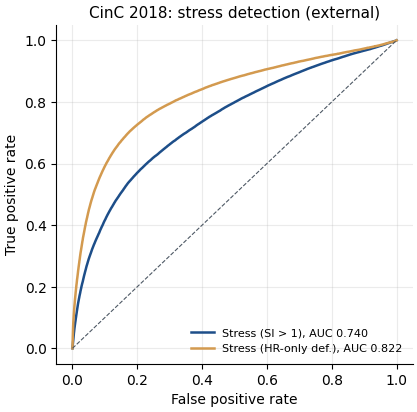

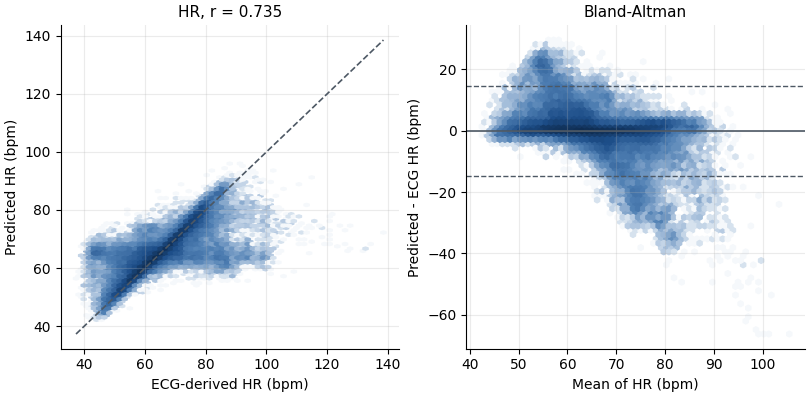

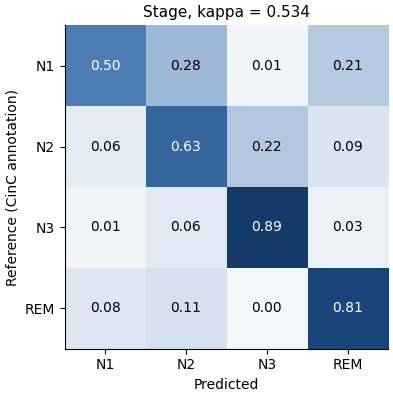

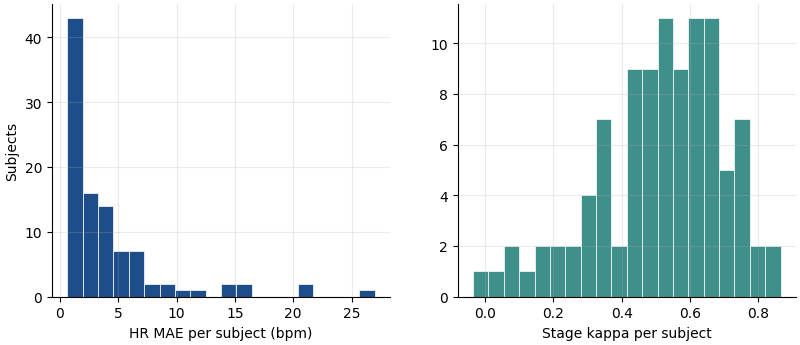

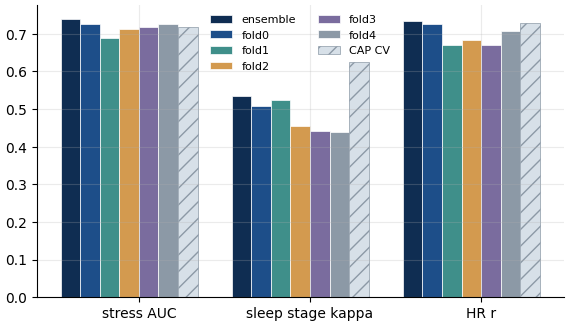

In [30]:
# Figures: stress ROC, HR agreement, stage confusion matrix, per-subject HR error and fold-model comparison (saved as PNG and PDF)
from matplotlib.colors import LinearSegmentedColormap
NAVY, TEAL, SAND, SLATE, MIST, PLUM, DEEP = "#1d4e89", "#3f8f8a", "#d39a4f", "#8c99a6", "#d7e0e8", "#7a6c9e", "#0f2d52"
REF = "#4d5864"
CMAP = LinearSegmentedColormap.from_list("thesis", ["#f5f8fb", "#a9c1dc", "#4f7fb3", NAVY, DEEP])
FOLDC = [NAVY, TEAL, SAND, PLUM, SLATE]
plt.rcParams.update({"savefig.dpi": 300, "savefig.bbox": "tight", "savefig.pad_inches": 0.05, "pdf.fonttype": 42,
                     "font.family": "DejaVu Sans", "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10,
                     "legend.fontsize": 8, "legend.frameon": False, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.prop_cycle": plt.cycler(color=FOLDC)})

def save(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(OUT / f"{name}.{ext}")
    plt.show()
    plt.close(fig)

fig, ax = plt.subplots(figsize=(4.6, 4.4))
for col, yc, lab, c in (("si_pred", "y_stress", "Stress (SI > 1)", NAVY), ("zhr_pred", "y_hr", "Stress (HR-only def.)", SAND)):
    fpr, tpr, _ = roc_curve(E[yc], E[col])
    ax.plot(fpr, tpr, color=c, lw=1.8, label=f"{lab}, AUC {roc_auc_score(E[yc], E[col]):.3f}")
ax.plot([0, 1], [0, 1], color=REF, ls="--", lw=0.8)
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate"); ax.legend(loc="lower right")
ax.set_title("CinC 2018: stress detection (external)")
save(fig, "ext_fig1_stress_roc")

fig, axs = plt.subplots(1, 2, figsize=(9.6, 4.2))
sel = E.sample(min(60000, len(E)), random_state=SEED)
axs[0].hexbin(sel.hr, sel.hr_pred, gridsize=60, cmap=CMAP, mincnt=1, bins="log")
lim = [min(sel.hr.min(), sel.hr_pred.min()), max(sel.hr.max(), sel.hr_pred.max())]
axs[0].plot(lim, lim, color=REF, lw=1.2, ls="--")
axs[0].set_xlabel("ECG-derived HR (bpm)"); axs[0].set_ylabel("Predicted HR (bpm)"); axs[0].set_title(f"HR, r = {res_full['HR r']:.3f}")
m, dlt = (sel.hr + sel.hr_pred) / 2, sel.hr_pred - sel.hr
axs[1].hexbin(m, dlt, gridsize=60, cmap=CMAP, mincnt=1, bins="log")
bias, sd = dlt.mean(), dlt.std()
axs[1].axhline(bias, color=REF, lw=1.2)
for v in (bias + 1.96 * sd, bias - 1.96 * sd):
    axs[1].axhline(v, color=REF, lw=1.0, ls="--")
axs[1].set_xlabel("Mean of HR (bpm)"); axs[1].set_ylabel("Predicted - ECG HR (bpm)"); axs[1].set_title("Bland-Altman")
save(fig, "ext_fig2_hr_agreement")

cm = confusion_matrix(E.stg, E.stage_pred, labels=range(4))
cmn = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(4.8, 4.2))
ax.imshow(cmn, cmap=CMAP, vmin=0, vmax=1)
ax.grid(False)
ax.set_xticks(range(4)); ax.set_xticklabels(M.STAGES); ax.set_yticks(range(4)); ax.set_yticklabels(M.STAGES)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center", color="white" if cmn[i, j] > 0.5 else "black")
ax.set_xlabel("Predicted"); ax.set_ylabel("Reference (CinC annotation)"); ax.set_title(f"Stage, kappa = {res_full['sleep stage kappa']:.3f}")
save(fig, "ext_fig3_stage_confusion")
pd.DataFrame(cm, index=M.STAGES, columns=M.STAGES).to_csv(OUT / "external_stage_confusion_counts.csv")

fig, axs = plt.subplots(1, 2, figsize=(9.6, 3.8))
axs[0].hist(per["HR MAE"], bins=20, color=NAVY, edgecolor="white", linewidth=0.5)
axs[0].set_xlabel("HR MAE per subject (bpm)"); axs[0].set_ylabel("Subjects")
axs[1].hist(per["stage kappa"], bins=20, color=TEAL, edgecolor="white", linewidth=0.5)
axs[1].set_xlabel("Stage kappa per subject")
save(fig, "ext_fig4_per_subject")

names = ["stress AUC", "sleep stage kappa", "HR r"]
cols = list(folds.columns)
fig, ax = plt.subplots(figsize=(6.8, 3.8))
w = 0.8 / (len(cols) + 1)
for i, n in enumerate(cols):
    c = DEEP if n == "ensemble" else FOLDC[int(n.replace("fold", "")) % len(FOLDC)]
    ax.bar(np.arange(len(names)) + i * w, folds.loc[names, n], w, label=n, color=c, edgecolor="white", linewidth=0.5)
ax.bar(np.arange(len(names)) + len(cols) * w, [CAP_REF[n] for n in names], w, label="CAP CV", color=MIST, edgecolor=SLATE, hatch="//", linewidth=0.5)
ax.set_xticks(np.arange(len(names)) + 0.4); ax.set_xticklabels(names); ax.legend(ncol=2)
save(fig, "ext_fig5_fold_models")

In [31]:
# Summary text for the thesis and the limitations that must be stated with these numbers
r = res_full
print(f"External validation on {E.record.nunique()} CinC 2018 training subjects ({len(E):,} windows), CAP-trained v3 ensemble, no retraining.")
print(f"HR: MAE {r['HR MAE (bpm)']:.2f} bpm, r {r['HR r']:.3f} | RMSSD r {r['RMSSD r']:.3f} | stress AUC {r['stress AUC']:.3f} (HR-only {r['stress AUC (HR-only def.)']:.3f})")
print(f"Sleep stage: acc {r['sleep stage acc']:.3f}, kappa {r['sleep stage kappa']:.3f}, macro F1 {r['sleep stage macro F1']:.3f}")
print("\nLimitations to state:")
for s in ("Population shift: CinC 2018 consists of patients referred for suspected sleep disorders (mostly sleep-disordered breathing), mean age about 55, not the CAP population.",
          "The stress label is derived from ECG (HR and RMSSD), exactly as for CAP; it is a physiological proxy, not a clinical stress label.",
          "Staging: CAP uses R&K annotation, CinC uses AASM; N3 merges S3 and S4 in CAP, so stage agreement also reflects the scoring-rule difference.",
          "Chin EMG and ECG were recorded together; ECG leakage into the chin EMG could contribute to the HR prediction (not excluded here).",
          "Only a random subset of the training records was used; the disorder head was not evaluated (no matching labels)."):
    print("-", s)

External validation on 100 CinC 2018 training subjects (409,628 windows), CAP-trained v3 ensemble, no retraining.
HR: MAE 4.26 bpm, r 0.735 | RMSSD r 0.352 | stress AUC 0.740 (HR-only 0.822)
Sleep stage: acc 0.673, kappa 0.534, macro F1 0.658

Limitations to state:
- Population shift: CinC 2018 consists of patients referred for suspected sleep disorders (mostly sleep-disordered breathing), mean age about 55, not the CAP population.
- The stress label is derived from ECG (HR and RMSSD), exactly as for CAP; it is a physiological proxy, not a clinical stress label.
- Staging: CAP uses R&K annotation, CinC uses AASM; N3 merges S3 and S4 in CAP, so stage agreement also reflects the scoring-rule difference.
- Chin EMG and ECG were recorded together; ECG leakage into the chin EMG could contribute to the HR prediction (not excluded here).
- Only a random subset of the training records was used; the disorder head was not evaluated (no matching labels).
